# 03 — Custo do produtor (CONAB)

**Objetivo:** entender o que as planilhas de custo de produção da CONAB permitem analisar para Arroz, Feijão, Café e Leite (decisão 5).

**O que esta etapa faz:**
- lê todas as abas de `data/raw/conab/` com `src.data_loading`, sem editar os originais;
- confere **frequência**, **região**, **unidade** e **qualidade** dos dados;
- registra a planilha e o local escolhidos para cada produto;
- salva a tabela consolidada em `data/processed/conab_custos.csv`.

- compara os modelos da Q1 **com e sem** CONAB, como combinado com a parte C;
- compara a variação anual do custo com a do preço de mercado (Arroz e Feijão).

**Conclusão:** a CONAB fica **fora dos modelos finais da Q1** (seções 8 a 10 e decisão 5).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Permite importar o pacote src/ a partir da pasta notebooks/
sys.path.append(str(Path.cwd().parent))

from src import config
from src.aggregation import serie_geral
from src.conab_analise import comparar_modelos_com_sem_conab, comparar_variacao_anual
from src.data_loading import (
    carregar_base_limpa,
    carregar_conab_completo,
    diferencas_entre_abas_leite,
    inspecionar_abas_leite,
    listar_arquivos_conab,
    selecionar_series_conab,
)

pd.set_option("display.max_rows", 100, "display.max_columns", 30)

## 1. Leitura

Cada aba vira uma linha. Abas com problema **não são corrigidas nem apagadas**: ficam na tabela com `valido = False` e o motivo em `problema`.

In [2]:
arquivos = listar_arquivos_conab()
conab = carregar_conab_completo()

print(f"{len(arquivos)} planilhas, {len(conab)} abas, {conab['valido'].sum()} válidas")
conab.to_csv(config.ARQUIVO_CONAB_CONSOLIDADO, index=False, encoding="utf-8")

7 planilhas, 1015 abas, 809 válidas


## 2. Inventário por planilha

In [3]:
conab.groupby(["produto", "planilha"]).agg(
    abas=("aba", "size"),
    validas=("valido", "sum"),
    locais=("regiao", "nunique"),
    primeiro_ano=("ano", "min"),
    ultimo_ano=("ano", "max"),
)

abas  validas  \
produto planilha                                                           
Arroz   Arroz_Irrigado_Serie_Historica_2002-2026.xls        204      156   
        Arroz_Sequeiro_Serie_Historica_2001-2026.xls        130      118   
Café    seriehistoricacustoscafearabica2003a2025.xls        197      190   
        seriehistoricacustoscafeconilon2007a2025.xls         88       67   
Feijão  Feijao_1_Safra_Serie_Historica-1998-2026.xls        324      210   
        Feijao_2_e_3_Safras_Serie_Historica_2013-2026.xls    47       44   
Leite   Serie_Historica_Leite_SP_2014-2025.xls               25       24   

                                                           locais  \
produto planilha                                                    
Arroz   Arroz_Irrigado_Serie_Historica_2002-2026.xls           18   
        Arroz_Sequeiro_Serie_Historica_2001-2026.xls           15   
Café    seriehistoricacustoscafearabica2003a2025.xls           11   
        seriehistoricacustoscafeconilon2007a2025.xls           11   
Feijão  Feijao_1_Safra_Serie_Historica-1998-2026.xls           29   
        Feijao_2_e_3_Safras_Serie_Historica_2013-2026.xls       6   
Leite   Serie_Historica_Leite_SP_2014-2025.xls                  5   

                                                           primeiro_ano  \
produto planilha                                                          
Arroz   Arroz_Irrigado_Serie_Historica_2002-2026.xls               2002   
        Arroz_Sequeiro_Serie_Historica_2001-2026.xls               1998   
Café    seriehistoricacustoscafearabica2003a2025.xls               2003   
        seriehistoricacustoscafeconilon2007a2025.xls               2007   
Feijão  Feijao_1_Safra_Serie_Historica-1998-2026.xls               1998   
        Feijao_2_e_3_Safras_Serie_Historica_2013-2026.xls          2004   
Leite   Serie_Historica_Leite_SP_2014-2025.xls                     2014   

                                                           ultimo_ano  
produto planilha                                                       
Arroz   Arroz_Irrigado_Serie_Historica_2002-2026.xls             2026  
        Arroz_Sequeiro_Serie_Historica_2001-2026.xls             2026  
Café    seriehistoricacustoscafearabica2003a2025.xls             2025  
        seriehistoricacustoscafeconilon2007a2025.xls             2025  
Feijão  Feijao_1_Safra_Serie_Historica-1998-2026.xls             2026  
        Feijao_2_e_3_Safras_Serie_Historica_2013-2026.xls        2026  
Leite   Serie_Historica_Leite_SP_2014-2025.xls                   2025

## 3. Frequência

Se a série fosse mensal, um mesmo local teria até 12 valores por ano. A tabela mostra quantos valores válidos cada combinação de planilha, local e variante tem por ano.

In [4]:
por_ano = (
    conab[conab["valido"]]
    .groupby(["planilha", "regiao", "variante", "ano"], dropna=False)
    .size()
)
por_ano.value_counts().rename_axis("valores_por_ano").to_frame("combinacoes")

,combinacoes
valores_por_ano,
1,809


In [5]:
# Mês de referência mais comum em cada produto, de 2022 em diante
recentes = conab[conab["valido"] & (conab["ano"] >= 2022)]
recentes.assign(mes=recentes["periodo"].dt.month).groupby("produto")["mes"].value_counts().rename("abas").to_frame()

abas
produto mes      
Arroz   3      47
        9       6
Café    11     33
        10     28
Feijão  3      36
        9       7
Leite   3       8

## 4. Unidades

O custo por saca é convertido para R$/kg com o tamanho de saca declarado em cada aba. O leite já vem em R$/l.

In [6]:
conab.groupby(["produto", "base_area", "unidade", "kg_unidade"], dropna=False).size().rename("abas").to_frame()

abas
produto base_area unidade kg_unidade      
Arroz   R$/ha     R$/kg   50.0         182
                          60.0         152
Café    R$/ha     R$/kg   60.0         262
                          NaN           23
Feijão  R$/ha     R$/kg   50.0           7
                          60.0         364
Leite   R$/ano    R$/l    1.0           25

## 5. Qualidade dos dados

- `sem_custo_total`, `sem_data`, `sem_unidade`: a aba não traz o dado de forma legível;
- `unidade_inconsistente`: a saca implícita difere mais de 5% da declarada;
- `copia_de_outra_aba`: valores idênticos aos de outra aba, com título de outro município;
- `repete_ano_anterior`: mesmo local com os valores do ano anterior;
- `titulo_divergente` e `dados_repetidos`: apenas alertas, a aba continua válida.

In [7]:
conab["problema"].fillna("sem problema").value_counts().to_frame("abas")

,abas
problema,
sem problema,795
sem_custo_total,137
sem_data,32
sem_unidade,23
titulo_divergente,10
unidade_inconsistente,7
dados_repetidos,4
sem_custo_total;titulo_divergente,3
copia_de_outra_aba,3


In [8]:
# Problemas nas abas de 2022 em diante, período que interessa à base de preços
colunas = ["produto", "aba", "periodo", "custo_area", "custo", "valido", "problema"]
conab[(conab["ano"] >= 2022) & conab["problema"].notna()][colunas]

,produto,aba,periodo,custo_area,custo,valido,problema
747,Café,SP-Franca 2023,2023-11,25998.700000,15.475412,False,copia_de_outra_aba
859,Café,Patrocínio-MG-2023,2023-11,25998.700000,15.475412,True,dados_repetidos
918,Café,Colatina-ES-2024,2024-10,38974.360000,10.826211,True,titulo_divergente
957,Café,Nova Brasilândia-RO-2025,2025-10,42008.280000,10.771355,False,unidade_inconsistente
991,Leite,Cunha-SP-2024,2024-03,172840.493441,2.423886,True,dados_repetidos
1003,Leite,Itapetininga-SP-2024,2024-03,172840.493441,2.423886,False,copia_de_outra_aba


### 5.1. Evidência: a aba Itapetininga-2024 apresenta os dados de Cunha

A CONAB não informa qual aba é a original, então a conclusão é uma **inferência** a partir do conteúdo da própria planilha. A tabela abaixo compara o município escrito dentro de cada aba, o tamanho da produção e o custo.

In [9]:
abas_leite = [
    "Itapetininga-SP-2022",
    "Itapetininga-SP-2023",
    "Itapetininga-SP-2024",
    "Cunha-SP-2023",
    "Cunha-SP-2024",
    "Cunha-SP-2025",
]
inspecionar_abas_leite(abas_leite)

,aba,municipio_no_titulo,producao_l_dia,custo_r_por_ano,custo_r_por_litro
0,Itapetininga-SP-2022,ITAPETININGA,555.0,474288.987234,2.191467
1,Itapetininga-SP-2023,ITAPETININGA,555.0,542219.734531,2.552885
2,Itapetininga-SP-2024,CUNHA,157.5,172840.493441,2.423886
3,Cunha-SP-2023,CUNHA,157.5,167934.558683,2.349351
4,Cunha-SP-2024,CUNHA,157.5,172840.493441,2.423886
5,Cunha-SP-2025,CUNHA,157.5,184518.912732,2.587907


A comparação célula por célula das duas abas de 2024 mostra o que há de diferente entre elas:

In [10]:
diferencas_entre_abas_leite("Itapetininga-SP-2024", "Cunha-SP-2024")

,linha,coluna,Itapetininga-SP-2024,Cunha-SP-2024
0,8,7,A partir de 2024 esse custo foi inativado.,


**Por que Itapetininga-2024 foi desconsiderada e Cunha-2024 foi mantida:**

1. **Título:** a aba se chama Itapetininga-2024, mas o campo "MUNICÍPIO" diz Cunha.
2. **Produção:** Itapetininga tem 555 l/dia em 2022 e 2023 e passa a 157,5 l/dia em 2024, o valor de Cunha nos três anos.
3. **Conteúdo:** as duas abas de 2024 são iguais, exceto por uma única célula.
4. **Nota na aba:** essa célula, presente só em Itapetininga, informa que o custo foi inativado a partir de 2024.

**Limitação da fonte:** o índice da planilha diz que Itapetininga foi inativada a partir de 2025, enquanto a nota da aba diz 2024. Isso não altera a escolha, pois Cunha é coerente nos três anos.

## 6. Planilha e local escolhidos

Critérios, em ordem: representar o produto vendido ao consumidor, cobrir a janela da base (set/2022 a ago/2026), ter dados válidos e, quando possível, ficar em São Paulo.

| Produto | Escolha | Motivo |
|---|---|---|
| Arroz | Irrigado, Pelotas-RS | Não há arroz irrigado em SP nas planilhas; o RS é o principal produtor e o local tem série contínua |
| Feijão | 1ª safra, Taquarituba-SP | Local em SP com série contínua até 2026 |
| Café | Arábica, Franca-SP | Local em SP; a aba de 2023 é inválida por repetir Patrocínio-MG |
| Leite | Cunha-SP | Local em SP com mais valores na janela: 3 (mar/2023 a mar/2025), contra 2 de São José do Rio Preto, inativado a partir de 2025 |

In [11]:
series = selecionar_series_conab(conab)
series[["produto", "regiao", "periodo", "custo", "unidade", "custo_area", "base_area"]]

,produto,regiao,periodo,custo,unidade,custo_area,base_area
0,Arroz,Pelotas-RS,2023-03,1.652723,R$/kg,13221.760000,R$/ha
1,Arroz,Pelotas-RS,2024-03,1.538594,R$/kg,12308.740000,R$/ha
2,Arroz,Pelotas-RS,2025-03,1.633425,R$/kg,13067.410000,R$/ha
3,Arroz,Pelotas-RS,2026-03,1.834270,R$/kg,14674.140000,R$/ha
4,Feijão,Taquarituba-SP,2023-03,5.140063,R$/kg,14135.190000,R$/ha
5,Feijão,Taquarituba-SP,2024-03,5.075543,R$/kg,13957.750000,R$/ha
6,Feijão,Taquarituba-SP,2025-03,5.269804,R$/kg,14491.970000,R$/ha
7,Feijão,Taquarituba-SP,2026-03,5.518181,R$/kg,15174.990000,R$/ha
8,Café,Franca-SP,2022-11,17.848825,R$/kg,32127.890000,R$/ha
9,Café,Franca-SP,2024-10,14.573369,R$/kg,26232.060000,R$/ha


In [12]:
# Quantos valores distintos cada produto tem na janela de 48 meses
series.groupby("produto").agg(
    valores=("custo", "size"),
    primeiro=("periodo", "min"),
    ultimo=("periodo", "max"),
)

,valores,primeiro,ultimo
produto,,,
Arroz,4,2023-03,2026-03
Café,3,2022-11,2025-10
Feijão,4,2023-03,2026-03
Leite,3,2023-03,2025-03


## 7. O que os dados mostram

- A CONAB publica **um valor por ano** para cada local; não há série mensal.
- Na janela da base, as séries escolhidas têm **3 ou 4 valores** por produto.
- Arroz e Feijão têm cobertura completa; Café perde 2023 e Leite termina em mar/2025.

## 8. Modelos da Q1 com e sem CONAB

A decisão 5 prevê comparar os modelos com e sem as colunas `custo_conab` e `meses_desde_relato_conab`. Para a comparação ser justa, os dois lados usam:
- os **mesmos 11 meses de teste** (origens de set/2025 a jul/2026), com corte por data;
- as **mesmas linhas de treino**, sem os meses anteriores ao primeiro custo disponível;
- os **mesmos hiperparâmetros**, escolhidos só no treino.

A defasagem 0 usa o custo no próprio mês de referência. A defasagem 3 simula um atraso de 3 meses até a informação estar disponível ou chegar ao mercado.

In [13]:
geral = serie_geral(carregar_base_limpa())
comparacao = comparar_modelos_com_sem_conab(geral, series)
comparacao.to_csv(config.DIR_TABELAS / "03_conab_com_sem.csv", index=False, encoding="utf-8")

ordem = ["baseline", "linear", "linear+CONAB", "knn", "knn+CONAB"]
mae = comparacao.pivot_table(index=["produto", "defasagem"], columns="modelo", values="MAE")[ordem]
mae.round(4)

modelo             baseline  linear  linear+CONAB     knn  knn+CONAB
produto defasagem                                                   
Arroz   0            0.2814  0.2931        0.3569  0.4741     0.3460
        3            0.2814  0.3080        0.3045  0.4951     0.3662
Café    0            1.8491  2.4409        2.3471  3.3941     2.0273
        3            1.8491  2.4524        2.6446  3.3941     1.9636
Feijão  0            0.3709  0.4015        0.4097  0.4730     0.4709
        3            0.3709  0.4319        0.3569  0.5343     0.4552
Leite   0            0.3100  0.3054        0.3506  0.4521     0.4095
        3            0.3100  0.2971        0.3262  0.4474     0.4388

In [14]:
# Resumo dos 8 cenários (4 produtos x 2 defasagens)
pd.Series({
    "CONAB reduz o erro da regressão linear": (mae["linear+CONAB"] < mae["linear"]).sum(),
    "CONAB reduz o erro do KNN": (mae["knn+CONAB"] < mae["knn"]).sum(),
    "melhor modelo SEM CONAB bate o baseline": (mae[["linear", "knn"]].min(axis=1) < mae["baseline"]).sum(),
    "melhor modelo COM CONAB bate o baseline": (mae[["linear+CONAB", "knn+CONAB"]].min(axis=1) < mae["baseline"]).sum(),
}, name="cenarios").to_frame()

,cenarios
CONAB reduz o erro da regressão linear,3
CONAB reduz o erro do KNN,8
melhor modelo SEM CONAB bate o baseline,2
melhor modelo COM CONAB bate o baseline,1


## 9. Variação anual: custo do produtor x preço de mercado

Compara março com março, o mês de referência das duas séries, para os produtos com cobertura completa. São só **3 comparações por produto**: a análise é ilustrativa e não mede causalidade nem defasagem.

In [15]:
variacao = comparar_variacao_anual(geral, series)
variacao.to_csv(config.DIR_TABELAS / "03_conab_variacao_anual.csv", index=False, encoding="utf-8")
variacao[["produto", "periodo_inicial", "periodo_final", "var_custo_pct", "var_preco_pct", "mesma_direcao"]].round(
    {"var_custo_pct": 1, "var_preco_pct": 1}
)

,produto,periodo_inicial,periodo_final,var_custo_pct,var_preco_pct,mesma_direcao
0,Arroz,2023-03,2024-03,-6.9,31.5,False
1,Arroz,2024-03,2025-03,6.2,-3.0,False
2,Arroz,2025-03,2026-03,12.3,-25.9,False
3,Feijão,2023-03,2024-03,-1.3,-4.2,True
4,Feijão,2024-03,2025-03,3.8,-23.5,False
5,Feijão,2025-03,2026-03,4.7,20.1,True


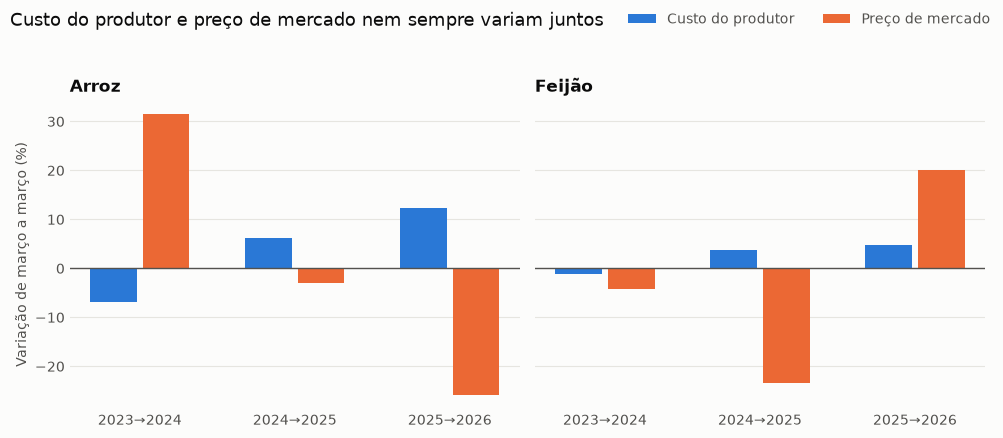

In [16]:
COR_CUSTO, COR_PRECO = "#2a78d6", "#eb6834"
TEXTO, TEXTO_SECUNDARIO, GRADE = "#0b0b0b", "#52514e", "#e6e5e0"

fig, eixos = plt.subplots(1, 2, figsize=(10, 4.4), sharey=True, facecolor="#fcfcfb")
for eixo, produto in zip(eixos, config.PRODUTOS_CONAB_DESCRITIVA):
    dados = variacao[variacao["produto"] == produto]
    x = np.arange(len(dados))
    eixo.set_facecolor("#fcfcfb")
    eixo.bar(x - 0.17, dados["var_custo_pct"], width=0.3, color=COR_CUSTO, label="Custo do produtor")
    eixo.bar(x + 0.17, dados["var_preco_pct"], width=0.3, color=COR_PRECO, label="Preço de mercado")
    eixo.axhline(0, color=TEXTO_SECUNDARIO, linewidth=1)
    eixo.grid(axis="y", color=GRADE, linewidth=0.8)
    eixo.set_axisbelow(True)
    eixo.set_xticks(x, [f"{i.year}→{f.year}" for i, f in zip(dados["periodo_inicial"], dados["periodo_final"])])
    eixo.set_title(produto, loc="left", color=TEXTO, fontweight="bold")
    eixo.tick_params(colors=TEXTO_SECUNDARIO, length=0)
    for lado in ("top", "right", "left", "bottom"):
        eixo.spines[lado].set_visible(False)

eixos[0].set_ylabel("Variação de março a março (%)", color=TEXTO_SECUNDARIO)
alcas, rotulos = eixos[0].get_legend_handles_labels()
fig.legend(alcas, rotulos, loc="upper right", ncol=2, frameon=False, labelcolor=TEXTO_SECUNDARIO)
fig.suptitle("Custo do produtor e preço de mercado nem sempre variam juntos", x=0.01, ha="left", color=TEXTO, fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(config.DIR_FIGURAS / "03_custo_preco_anual.png", dpi=160, facecolor=fig.get_facecolor())
plt.show()

## 10. Conclusão

- Nos 8 cenários, algum modelo com CONAB bate o baseline em **1** (Feijão, defasagem 3). Sem CONAB, algum modelo bate em **2** (Leite). Não há ganho consistente.
- A CONAB reduz o erro do KNN nos 8 cenários, mas o KNN continua pior que o baseline. Na regressão linear, reduz em 3 de 8.
- Custo e preço variaram na mesma direção em **0 de 3** comparações no Arroz e **2 de 3** no Feijão.
- Com 11 meses de teste e um valor de custo por ano, as diferenças não sustentam afirmar ganho nem perda.

**Decisão:** a CONAB fica **fora dos modelos finais da Q1** e permanece como evidência e análise descritiva. Isso **não significa que o custo do produtor não influencia o preço**, apenas que estes dados anuais não permitem medir esse efeito.